# CaloDiffusion — unified electron, photon and pion diagnostic study
## New-reference fidelity → response structure → tails → native-cell diagnostics → optional replay
Prepared by Vishal, 18 November 2026. This single notebook continues the completed `_2` fidelity studies without retraining or repeating full generation. It consolidates the electron outlier/final-actions, photon closeout, pion layer-profile/three-investigations and exact-replay workflows from your GitHub project at commit `1bf9faf58c133c2e38358fbf8e39f21a6021e967`.

**Inputs:** the complete photon archive `eval2_828d5a1a7978667f.zip` and complete pion/electron archive `eval2_pion_&_electron_e270d961f41a6597.zip`, or their original extracted result directories on Drive. CSV-only uploads support summaries but cannot establish native-cell or replay findings; this notebook deliberately requires the full banks. No raw `_2` download is needed for the default analysis.

**Run in Colab:** choose CPU for sections 1–10; GPU is needed only for optional section 11. Edit the two input paths below, mount Drive, and Run all. Outputs include per-particle explanations, figures, candidate lists, cell maps and a combined report. No old event ID or old hotspot is assumed to remain anomalous.

**Interpretation boundary:** this is exploratory follow-up to already inspected evaluation results. Reference quantile flags are screening tools, not calibrated anomaly probabilities. Fixed-reference seeds quantify generation variation, not training uncertainty. Official evaluation-file identity does not establish checkpoint-selection independence. No event is deleted or response clipped at one.


## 1. Locate both completed runs and freeze diagnostic choices
Use paths to your ZIP files or extracted run directories (the directory containing `manifest.json`). The defaults point to the earlier notebook's Drive output location; edit to match your actual location. A combined pion/electron run is supported directly. All three particles must be present once, preventing accidental mixing of duplicates.

Threshold sensitivity is evaluated at 1×, 2× and 5× the original analysis cut, never below the model ECUT. This is diagnostic only, not an optimization for best agreement. Candidate selection uses the two largest/smallest values per specified criterion and removes duplicate selections; explanations report the selection rule.


In [ ]:
from pathlib import Path
USE_GOOGLE_DRIVE = True
INPUTS = [
 Path('/content/drive/MyDrive/CaloDiffusion_new_reference/eval2_photon_828d5a1a7978667f.zip'),
 Path('/content/drive/MyDrive/CaloDiffusion_new_reference/eval2_pion_&_electron_e270d961f41a6597.zip'),
]
PARTICLES = ('electron','photon','pion')
OUTPUT_BASE = Path('/content/drive/MyDrive/CaloDiffusion/Calodiffusion_new_reference/Calodiffusion_detailed_study')
N_BOOT = 500
ANALYSIS_SEED = 20261118
TAIL_QUANTILES = (.01,.99)
CANDIDATES_PER_RULE = 2
CUT_FACTORS = (1.,2.,5.)
RUN_REPLAY = True  # Optional GPU stage; no full generation rerun.
REPLAY_EVENT_IDS = []  # Empty => highest-response generated candidate per particle.
REPLAY_RTOL = 2e-5
REPLAY_ATOL = 2e-6


## 2. Imports and utilities
Only missing CPU analysis packages are installed. Every result gets a fresh output directory. Existing input archives are read-only. ZIP extraction rejects paths outside the temporary extraction directory and symbolic links.


In [ ]:
import sys,subprocess,importlib.util,os,json,hashlib,zipfile,tempfile,shutil,io,gc,random,warnings
from datetime import datetime,timezone
from types import SimpleNamespace
from dataclasses import dataclass
from contextlib import contextmanager,redirect_stdout
for module,package in [('numpy','numpy'),('pandas','pandas'),('scipy','scipy'),('matplotlib','matplotlib'),('h5py','h5py')]:
 if importlib.util.find_spec(module) is None: subprocess.check_call([sys.executable,'-m','pip','install','-q',package])
import numpy as np,pandas as pd,h5py
from scipy import stats
from scipy.special import expit
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
if USE_GOOGLE_DRIVE:
 from google.colab import drive
 drive.mount('/content/drive')
else: OUTPUT_BASE=Path('/content/CaloDiffusion_detailed_study')
OUT=OUTPUT_BASE/datetime.now(timezone.utc).strftime('all_particles_%Y%m%dT%H%M%S%fZ')
for d in ['tables','figures','replay']: (OUT/d).mkdir(parents=True,exist_ok=True)
def sha(path):
 h=hashlib.sha256()
 with open(path,'rb') as f:
  for x in iter(lambda:f.read(4*1024**2),b''):h.update(x)
 return h.hexdigest()
def dump(path,obj):
 Path(path).write_text(json.dumps(obj,indent=2,default=lambda x:x.item() if isinstance(x,np.generic) else str(x)))
def seed(*parts):return int(hashlib.sha256('|'.join(map(str,(ANALYSIS_SEED,*parts))).encode()).hexdigest()[:8],16)
def savefig(name):
 plt.tight_layout();plt.savefig(OUT/'figures'/f'{name}.png',dpi=150,bbox_inches='tight');plt.show();plt.close()
def table(name,df):df.to_csv(OUT/'tables'/f'{name}.csv',index=False);return df
REPORT=['# Unified CaloDiffusion diagnostics','Exploratory analysis of completed official _2 evaluation runs.']
def note(s):REPORT.append(s);display(Markdown(s))


Mounted at /content/drive


## 3. Verify archives, provenance and the fixed-condition design
Integrity checks cover every listed artifact. Expected published MD5s are compared to the run manifests; the raw datasets are not included, so their original checksums are not recomputed here. Technical gates must all pass. Source revisions, software environments and scientific settings are recorded. Electron windows differ from discrete photon/pion energies, and detectors differ: raw radial distances, depths and occupancies must not be used to rank particles against one another.


In [ ]:
EXPECTED_MD5={'electron':'7a56fd68aa53ded37c2ac445694d9736','photon':'4767715ed56e99565fd9c67340661e70','pion':'fee7457b40127bc23c8ab909e2638ca0'}
EXPECTED_FILE={'electron':'dataset_2_2.hdf5','photon':'dataset_1_photons_2.hdf5','pion':'dataset_1_pions_2.hdf5'}
def run_folder(path):
 path=Path(path)
 if not path.exists():raise FileNotFoundError(f'Edit INPUTS: {path}')
 if path.is_dir():return path
 dest=Path(tempfile.mkdtemp(prefix='calo_diag_'))
 with zipfile.ZipFile(path) as z:
  for info in z.infolist():
   target=(dest/info.filename).resolve()
   if not target.is_relative_to(dest.resolve()) or (info.external_attr>>16)&0o170000==0o120000:
    raise ValueError('Unsafe ZIP member')
  z.extractall(dest)
 manifests=list(dest.rglob('manifest.json'))
 if len(manifests)!=1:raise ValueError('Expected one run manifest per archive')
 return manifests[0].parent
RUNS={};MANIFESTS={};OBS={};BANKS={};GEO={};EVENT_INDEX={};validation=[]
for path in INPUTS:
 root=run_folder(path);m=json.loads((root/'manifest.json').read_text())
 checks=json.loads((root/'artifact_sha256.json').read_text())
 for name,expected in checks.items():
  f=(root/name).resolve()
  if not f.is_relative_to(root.resolve()) or sha(f)!=expected:raise ValueError(f'Integrity failed: {name}')
 gates=json.loads((root/'validation_gates.json').read_text())
 if not gates or not all(g['passed'] for g in gates):raise ValueError('Failed or missing technical gates')
 for p in m['plan']['particles']:
  if p not in PARTICLES:continue
  if p in RUNS:raise ValueError(f'Duplicate run for {p}')
  ref=m['references'][p]
  assert ref['filename']==EXPECTED_FILE[p] and ref['md5']==EXPECTED_MD5[p]
  assert m['plan']['profile']=='fidelity'
  RUNS[p]=root;MANIFESTS[p]=m
  OBS[p]=pd.read_csv(root/'tables'/f'{p}_all_fidelity_observables.csv')
  BANKS[p]=pd.read_csv(root/'tables/native_bank_index.csv').query('particle==@p').copy()
  GEO[p]=json.loads((root/f'{p}_geometry.json').read_text())
  EVENT_INDEX[p]=pd.read_csv(root/'tables/generation_event_index.csv').query('particle==@p').copy()
  df=OBS[p];assert df.event_id.is_unique
  for label,g in df.groupby('stratum'):
   r=g[g.method=='reference'];a=g[g.method=='generator'];cfg=m['plan']['config']
   assert len(r)==cfg['n_test'] and r.event_id.str.startswith(ref['sha256']+':').all()
   assert set(a.generation_seed.astype(int))==set(m['plan']['seeds'][p])
   for (_,repeat),v in a.groupby(['generation_seed','repeat']):
    assert len(v)==len(r) and set(v.target_id)==set(r.event_id)
    assert np.allclose(v.set_index('target_id').loc[r.event_id].energy_GeV,r.energy_GeV)
   assert (a.groupby('target_id').size()==len(m['plan']['seeds'][p])*cfg['generation_repeats']).all()
  validation.append(dict(particle=p,run=m['run_id'],artifacts_verified=len(checks),gates_passed=len(gates),
    source_revision=m['plan']['repo_commit'],reference=ref['filename'],reference_sha256=ref['sha256']))
assert set(RUNS)==set(PARTICLES),'Supply complete archives for all selected particles.'
assert len({m['plan']['repo_commit'] for m in MANIFESTS.values()})==1
for key in ['sample_offset','n_test','generation_repeats','batch_size']:
 assert len({m['plan']['config'][key] for m in MANIFESTS.values()})==1,key
for p,m in MANIFESTS.items():
 assert len(m['plan']['seeds'][p])==3 and m['plan']['config']['generation_repeats']==2
 assert m['plan']['analysis_cuts_GeV'][p]=={'electron':1.51e-5,'photon':.01,'pion':.01}[p]
display(table('input_validation',pd.DataFrame(validation)))
dump(OUT/'analysis_plan.json',dict(inputs=list(map(str,INPUTS)),particles=PARTICLES,n_boot=N_BOOT,
 seed=ANALYSIS_SEED,tail_quantiles=TAIL_QUANTILES,cut_factors=CUT_FACTORS,
 candidates_per_rule=CANDIDATES_PER_RULE,interpretation='exploratory',input_manifests=MANIFESTS))


,particle,run,artifacts_verified,gates_passed,source_revision,reference,reference_sha256
0,photon,eval2_828d5a1a7978667f,447,15,1bf9faf58c133c2e38358fbf8e39f21a6021e967,dataset_1_photons_2.hdf5,b49f6739c5dfd57f1b2c809ab7b8243c60a8895e1967ff...
1,pion,eval2_e270d961f41a6597,883,30,1bf9faf58c133c2e38358fbf8e39f21a6021e967,dataset_1_pions_2.hdf5,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...
2,electron,eval2_e270d961f41a6597,883,30,1bf9faf58c133c2e38358fbf8e39f21a6021e967,dataset_2_2.hdf5,7561885bda9e2cfa2b0464d7ba779cd4066d89e91ce610...


## 4. Recompute native observables and enrich the saved event tables
Reconstruct layer/angle/radius maps from archived XML geometry and verify the saved mapping. Recompute response, occupancy, depth and RMS radius directly from native banks. New diagnostics include the largest-cell energy fraction, effective number of contributing cells, outer-radial-band fraction and final-layer fraction. The outer band is the outermost 20% of each layer's radial coordinate range; it is a geometric convention, not a detector-independent physics boundary. Native values retain the original model cutoff; analysis cuts are applied equally.


In [ ]:
DATA={};CELL_MAP={}
def cell_map(p):
 g=GEO[p];rows=[];k=0
 for j,(lid,na,edges) in enumerate(zip(g['layer_ids'],g['n_angles'],g['radial_edges'])):
  for angle in range(na):
   for radial,(lo,hi) in enumerate(zip(edges[:-1],edges[1:])):
    rows.append(dict(cell=k,layer=j,layer_id=lid,angle_bin=angle,radial_bin=radial,
      radius=(lo+hi)/2,r_low=lo,r_high=hi,outer=((lo+hi)/2>=.8*edges[-1])))
    k+=1
 c=pd.DataFrame(rows)
 assert np.allclose(c.radius,g['radius']) and np.array_equal(c.layer,g['layer_ordinal'])
 return c
for p in PARTICLES:
 CELL_MAP[p]=cell_map(p);table(f'{p}_cell_map',CELL_MAP[p]);DATA[p]={}
 for label,g in OBS[p].groupby('stratum'):
  ordered=[];chunks=[]
  for _,b in BANKS[p].query('stratum==@label').iterrows():
   with np.load(RUNS[p]/b.path,allow_pickle=False) as z:
    ids=z['event_id'].astype(str);raw=z['native'].copy();energy=z['energy']
    frame=g.set_index('event_id').loc[ids].reset_index()
    assert np.allclose(frame.energy_GeV,energy) and np.array_equal(frame.target_id.astype(str),z['target_id'].astype(str))
   ordered.append(frame);chunks.append(raw)
  f=pd.concat(ordered,ignore_index=True);raw=np.concatenate(chunks);assert set(f.event_id)==set(g.event_id)
  cut=MANIFESTS[p]['plan']['analysis_cuts_GeV'][p];a=np.where(raw>=cut,raw,0.)
  assert np.isfinite(a).all() and (a>=0).all()
  total=a.sum(1);inv=np.divide(1.,total,out=np.full_like(total,np.nan),where=total>0);cm=CELL_MAP[p]
  recomputed={'response':total/f.energy_GeV.to_numpy(),'occupancy':(a>=cut).mean(1),
    'depth_layer':(a@cm.layer.to_numpy())*inv,'r_rms':np.sqrt((a@(cm.radius.to_numpy()**2))*inv)}
  for key,val in recomputed.items():assert np.allclose(f[key],val,rtol=2e-5,atol=1e-7,equal_nan=True),(p,label,key)
  layers=np.stack([a[:,cm.layer==j].sum(1)*inv for j in range(len(GEO[p]['layer_ids']))],1)
  f['max_cell_fraction']=a.max(1)*inv;f['max_cell']=a.argmax(1)
  f['effective_cells']=np.divide(total**2,(a*a).sum(1),out=np.full_like(total,np.nan),where=total>0)
  f['outer_fraction']=(a[:,cm.outer].sum(1))*inv;f['last_layer_fraction']=layers[:,-1]
  DATA[p][label]=dict(frame=f,raw=raw,a=a,layers=layers)
 OBS[p]=pd.concat([v['frame'] for v in DATA[p].values()],ignore_index=True)
 table(f'{p}_enriched_observables',OBS[p])
note('Native-bank recalculation agrees with the archived response, occupancy, depth and RMS-radius tables for every selected particle and stratum.')


Native-bank recalculation agrees with the archived response, occupancy, depth and RMS-radius tables for every selected particle and stratum.

## 5. Response location, width and shape — conditional bootstrap and seed stability
For uncertainty, resample reference target IDs and carry all six generated showers for each target with them. This preserves the fixed-condition design. Report signed mean, standard-deviation and quantile differences; a percentile interval excluding zero is a descriptive signal, not a multiple-testing-corrected discovery. The bootstrap treats the checkpoint and selected energy strata as fixed. Quantile intervals with only 300 reference rows are fragile in the far tails.

Electron energy windows mix incident energies: supplementary within-window slices below check whether a mean shift hides an energy trend. These slices share the existing data and are exploratory.


### Electron: response and shape

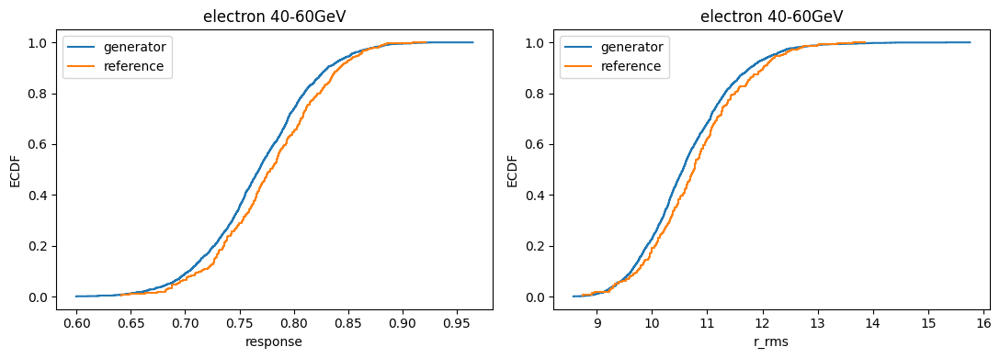

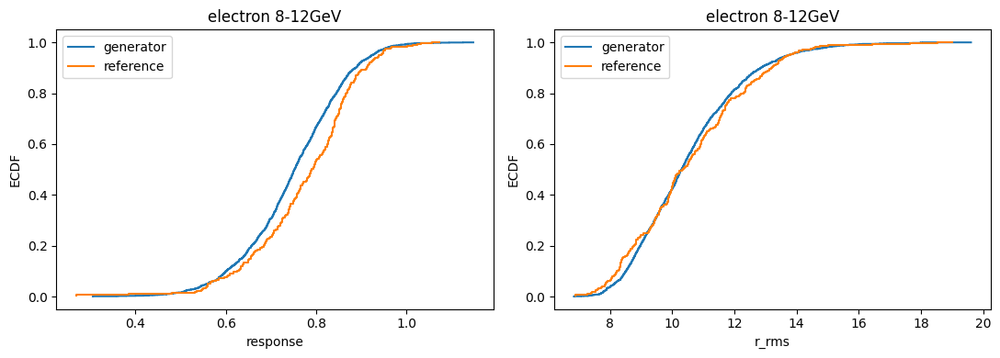

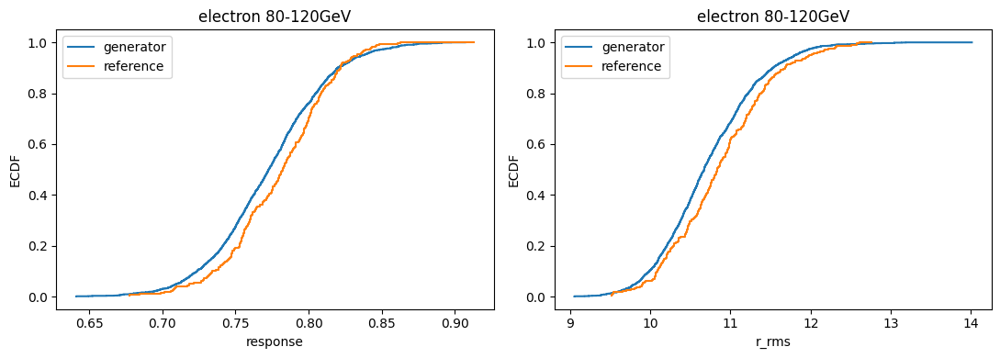

### Photon: response and shape

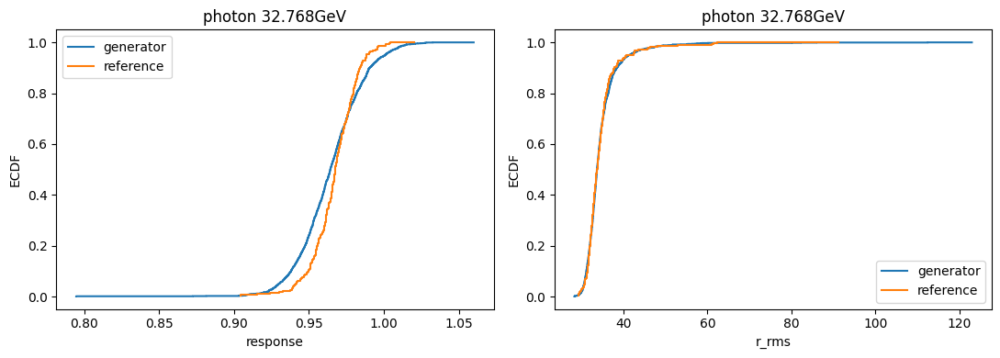

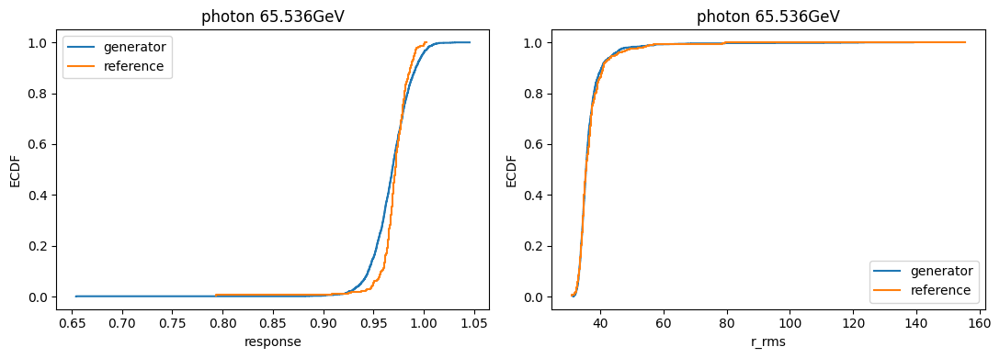

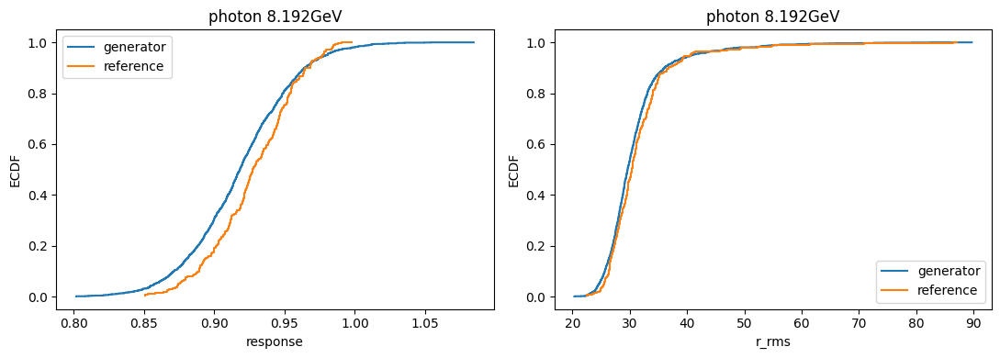

### Pion: response and shape

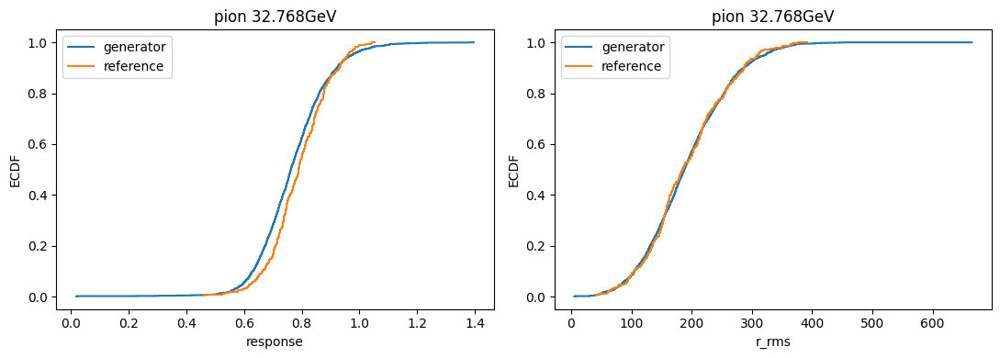

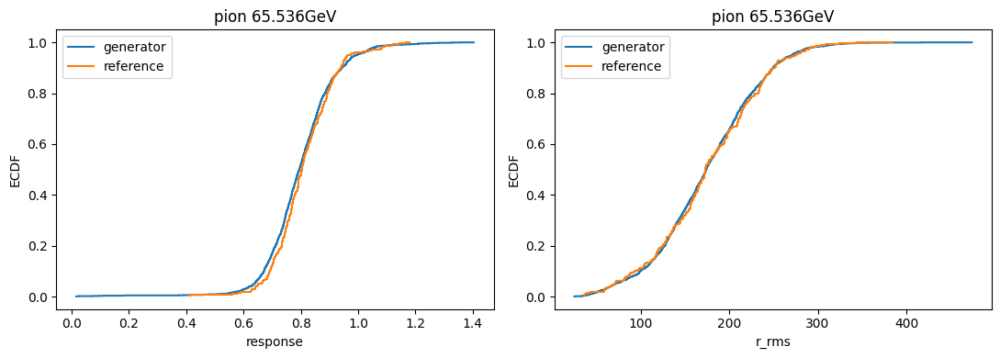

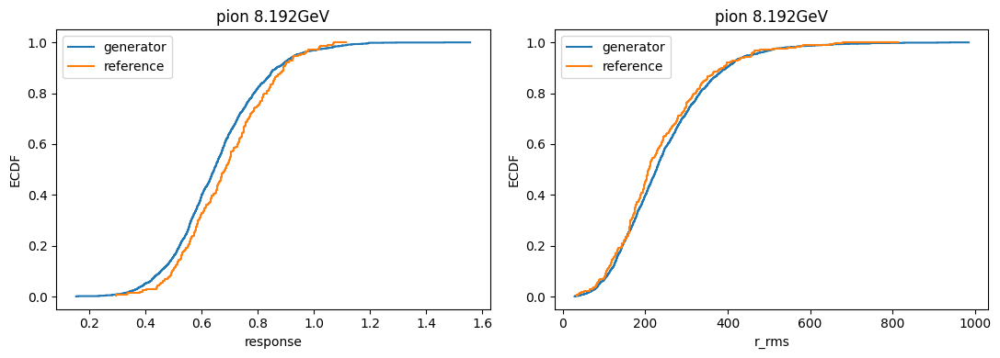

**electron response interpretation:** 40-60GeV: reference 0.7794, generated 0.7684, difference -0.0109 (conditional 95% interval -0.0165 to -0.0049); 8-12GeV: reference 0.7778, generated 0.7495, difference -0.0283 (conditional 95% interval -0.0415 to -0.0145); 80-120GeV: reference 0.7806, generated 0.7729, difference -0.0077 (conditional 95% interval -0.0122 to -0.0034).

,particle,stratum,observable,statistic,reference,generated,difference,lo,hi
0,electron,40-60GeV,response,mean,0.779361,0.768422,-0.010938,-0.016538,-0.004869
40,electron,8-12GeV,response,mean,0.777818,0.749477,-0.028340,-0.041515,-0.014508
80,electron,80-120GeV,response,mean,0.780615,0.772920,-0.007695,-0.012212,-0.003410


**photon response interpretation:** 32.768GeV: reference 0.9674, generated 0.9645, difference -0.0029 (conditional 95% interval -0.0048 to -0.0012); 65.536GeV: reference 0.9713, generated 0.9681, difference -0.0031 (conditional 95% interval -0.0052 to -0.0008); 8.192GeV: reference 0.9283, generated 0.9187, difference -0.0096 (conditional 95% interval -0.0134 to -0.0058).

,particle,stratum,observable,statistic,reference,generated,difference,lo,hi
120,photon,32.768GeV,response,mean,0.967440,0.964517,-0.002923,-0.004754,-0.001174
160,photon,65.536GeV,response,mean,0.971266,0.968138,-0.003128,-0.005221,-0.000757
200,photon,8.192GeV,response,mean,0.928313,0.918713,-0.009599,-0.013391,-0.005752


**pion response interpretation:** 32.768GeV: reference 0.7917, generated 0.7700, difference -0.0217 (conditional 95% interval -0.0331 to -0.0090); 65.536GeV: reference 0.8135, generated 0.8000, difference -0.0135 (conditional 95% interval -0.0278 to -0.0004); 8.192GeV: reference 0.6908, generated 0.6565, difference -0.0342 (conditional 95% interval -0.0543 to -0.0137).

,particle,stratum,observable,statistic,reference,generated,difference,lo,hi
240,pion,32.768GeV,response,mean,0.791749,0.770023,-0.021726,-0.033081,-0.009004
280,pion,65.536GeV,response,mean,0.813509,0.800023,-0.013486,-0.027791,-0.000376
320,pion,8.192GeV,response,mean,0.690760,0.656526,-0.034234,-0.054330,-0.013653


In [ ]:
def paired_arrays(f,col):
 r=f[f.method=='reference'];g=f[f.method=='generator'];ids=r.event_id.tolist()
 x=r[col].to_numpy();y=np.stack([g[g.target_id==i][col].to_numpy() for i in ids])
 return x,y
METRICS=['response','occupancy','depth_layer','r_rms','r_sigma','max_cell_fraction','outer_fraction','last_layer_fraction']
def summary(x):
 x=np.asarray(x).ravel();x=x[np.isfinite(x)]
 return np.array([x.mean(),x.std(ddof=1),*np.quantile(x,[.01,.5,.99])]) if len(x)>1 else np.full(5,np.nan)
DIFF=[];SEED=[]
for p in PARTICLES:
 note(f'### {p.capitalize()}: response and shape')
 for label,v in DATA[p].items():
  f=v['frame']
  for col in METRICS:
   x,y=paired_arrays(f,col);rng=np.random.default_rng(seed(p,label,col));point=summary(y)-summary(x)
   draws=[]
   for _ in range(N_BOOT):
    take=rng.integers(0,len(x),len(x));draws.append(summary(y[take])-summary(x[take]))
   lo,hi=np.nanquantile(draws,[.025,.975],axis=0)
   for j,name in enumerate(['mean','std','q01','median','q99']):
    DIFF.append(dict(particle=p,stratum=label,observable=col,statistic=name,reference=summary(x)[j],
      generated=summary(y)[j],difference=point[j],lo=lo[j],hi=hi[j]))
  for gs,g in f[f.method=='generator'].groupby('generation_seed'):
   SEED.append(dict(particle=p,stratum=label,seed=int(gs),mean_response=g.response.mean(),std_response=g.response.std()))
  fig,axes=plt.subplots(1,2,figsize=(11,4))
  for ax,col in zip(axes,['response','r_rms']):
   for method,g in f.groupby('method'):
    a=np.sort(g[col].dropna());ax.step(a,np.arange(1,len(a)+1)/len(a),label=method)
   ax.set(xlabel=col,ylabel='ECDF',title=f'{p} {label}');ax.legend()
  savefig(f'{p}_{label}_response_radius')
DIFF=table('bootstrap_differences',pd.DataFrame(DIFF));SEED=table('generation_seed_stability',pd.DataFrame(SEED))
for p in PARTICLES:
 rows=DIFF.query('particle==@p and observable=="response" and statistic=="mean"')
 note(f'**{p} response interpretation:** '+ '; '.join(f'{r.stratum}: reference {r.reference:.4f}, generated {r.generated:.4f}, difference {r.difference:+.4f} (conditional 95% interval {r.lo:+.4f} to {r.hi:+.4f})' for r in rows.itertuples())+'.')
 display(rows)
ENERGY=[]
if 'electron' in DATA:
 for label,v in DATA['electron'].items():
  f=v['frame'];ref=f[f.method=='reference'];edges=np.quantile(ref.energy_GeV,[0,1/3,2/3,1]);edges[-1]=np.nextafter(edges[-1],np.inf)
  for j in range(3):
   for method,g in f[(f.energy_GeV>=edges[j])&(f.energy_GeV<edges[j+1])].groupby('method'):
    ENERGY.append(dict(stratum=label,slice=j,energy_low=edges[j],energy_high=edges[j+1],method=method,n=len(g),mean_response=g.response.mean()))
 table('electron_within_window_response',pd.DataFrame(ENERGY))


## 6. Tail frequencies, equal-count extrema and explicit candidate screening
Reference 1%/99% thresholds screen both tails; uncertainty resamples the reference threshold and generated targets together. Flags are not calibrated p-values and are not grounds for deleting events. The comparison of minima/maxima additionally subsamples 300 generated showers without replacement, matching the reference count; it remains conditional on the generated pool, not a null hypothesis test.

All low/high response, broad-radius, deep-shower and single-cell concentration candidates are selected anew from these `_2` runs. Reference extremes are selected alongside generator extremes. The old photon cell 367, electron cell 1565 and pion cell 523 are not hard-coded.


In [ ]:
TAIL=[];FLAGS=[];EXTREMA=[];CAND=[]
RULES=[('response','low'),('response','high'),('r_rms','high'),('depth_layer','high'),('max_cell_fraction','high')]
for p in PARTICLES:
 for label,v in DATA[p].items():
  f=v['frame']
  for col in METRICS:
   x,y=paired_arrays(f,col);q=np.nanquantile(x,TAIL_QUANTILES);rng=np.random.default_rng(seed('tails',p,label,col))
   rates=[]
   for _ in range(N_BOOT):
    ix=rng.integers(0,len(x),len(x));qb=np.nanquantile(x[ix],TAIL_QUANTILES);yb=y[ix].ravel();yb=yb[np.isfinite(yb)]
    rates.append([(yb<qb[0]).mean(),(yb>qb[1]).mean()])
   for j,side in enumerate(['low','high']):
    valid=y[np.isfinite(y)];rate=(valid<q[0]).mean() if j==0 else (valid>q[1]).mean()
    bounds=np.quantile(np.array(rates)[:,j],[.025,.975])
    TAIL.append(dict(particle=p,stratum=label,observable=col,side=side,reference_threshold=q[j],generated_rate=rate,lo=bounds[0],hi=bounds[1]))
   for gs,g in f[f.method=='generator'].groupby('generation_seed'):
    FLAGS.append(dict(particle=p,stratum=label,observable=col,seed=int(gs),n_valid=g[col].notna().sum(),low=int((g[col]<q[0]).sum()),high=int((g[col]>q[1]).sum())))
  for col in ['response','r_rms']:
   x,y=paired_arrays(f,col);pool=y.ravel();rng=np.random.default_rng(seed('equal_n',p,label,col));draw=np.array([[a.min(),a.max()] for a in [rng.choice(pool,len(x),replace=False) for _ in range(N_BOOT)]])
   EXTREMA.append(dict(particle=p,stratum=label,observable=col,reference_min=np.nanmin(x),reference_max=np.nanmax(x),
    generated_equal_n_min_median=np.median(draw[:,0]),generated_equal_n_max_median=np.median(draw[:,1]),
    max_lo=np.quantile(draw[:,1],.025),max_hi=np.quantile(draw[:,1],.975)))
  for method,g in f.groupby('method'):
   for col,side in RULES:
    chosen=g.nsmallest(CANDIDATES_PER_RULE,col) if side=='low' else g.nlargest(CANDIDATES_PER_RULE,col)
    for _,r in chosen.iterrows():CAND.append(dict(particle=p,stratum=label,method=method,event_id=r.event_id,rule=f'{col}_{side}',value=r[col]))
TAIL=table('reference_quantile_tail_rates',pd.DataFrame(TAIL));table('tail_counts_per_seed',pd.DataFrame(FLAGS));table('equal_count_extrema',pd.DataFrame(EXTREMA))
CAND=table('candidate_selection_rules',pd.DataFrame(CAND));display(TAIL.query('observable=="response"'))
note('Tail flags identify events for inspection only. Compare rates and equal-count distributions; a larger generated maximum from 1,800 events versus 300 reference events is not sufficient evidence of a defect.')


,particle,stratum,observable,side,reference_threshold,generated_rate,lo,hi
0,electron,40-60GeV,response,low,0.674421,0.034444,0.007778,0.052778
1,electron,40-60GeV,response,high,0.883201,0.011667,0.001667,0.026111
16,electron,8-12GeV,response,low,0.530788,0.029444,0.000556,0.047514
17,electron,8-12GeV,response,high,1.023701,0.003333,0.001111,0.023069
32,electron,80-120GeV,response,low,0.701457,0.030556,0.010556,0.049444
33,electron,80-120GeV,response,high,0.848747,0.029444,0.008889,0.044444
48,photon,32.768GeV,response,low,0.929791,0.047778,0.008889,0.112806
49,photon,32.768GeV,response,high,1.001274,0.047778,0.009708,0.081667
64,photon,65.536GeV,response,low,0.927896,0.021667,0.002486,0.116167
65,photon,65.536GeV,response,high,1.000198,0.038889,0.025556,0.095000


Tail flags identify events for inspection only. Compare rates and equal-count distributions; a larger generated maximum from 1,800 events versus 300 reference events is not sufficient evidence of a defect.

## 7. Longitudinal profiles, radial bands and joint correlations
Layer profiles use event-normalized fractions. Signed generator–reference differences have target-cluster bootstrap intervals. Layer ordinals are not physical distances. Radial bands are fixed within each detector: electron [0,10,20,30,∞), photon [0,50,100,200,400,∞), pion [0,100,200,400,600,∞), in XML radial units. No cross-detector ranking is implied.

Spearman difference intervals are bootstrapped on the same target clusters. Inspect both marginal distributions and joint relationships; many simultaneous intervals are exploratory and unadjusted for multiplicity.


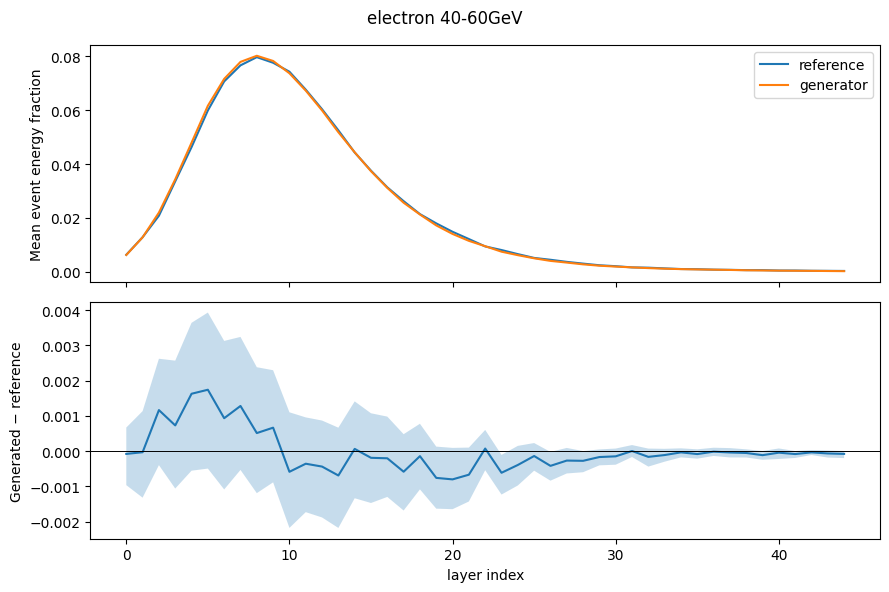

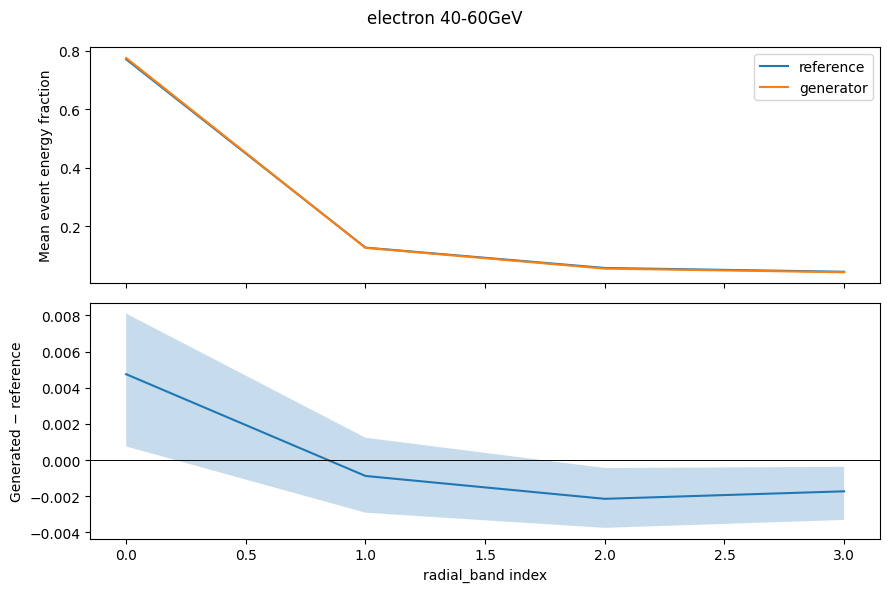

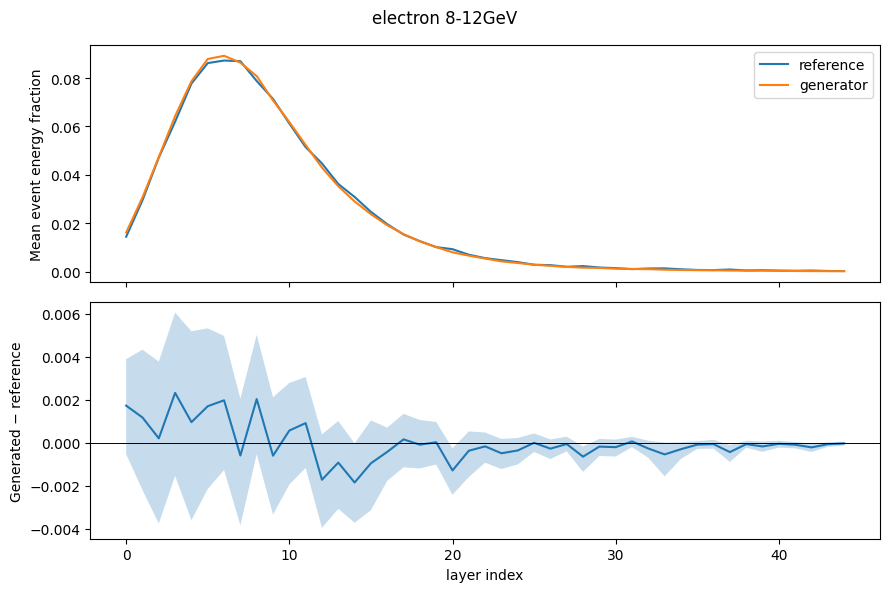

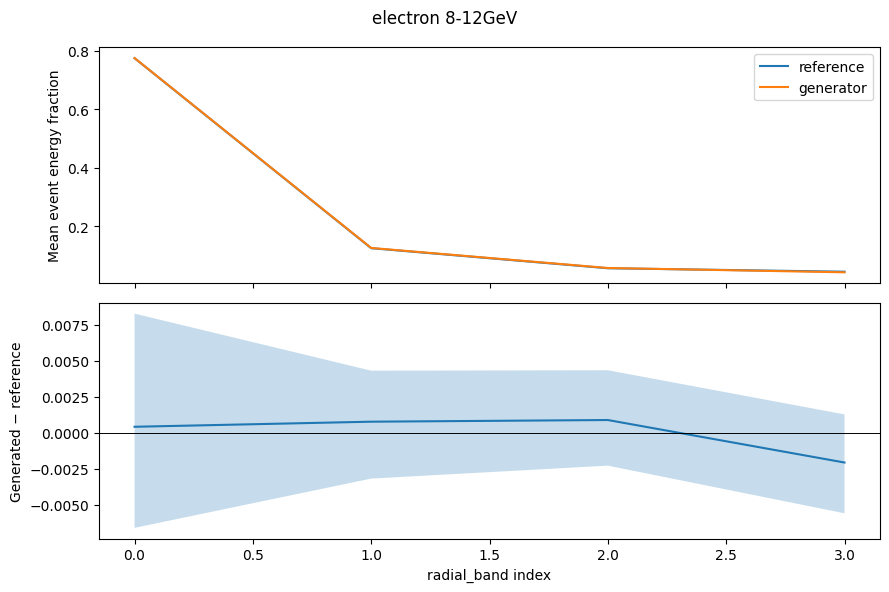

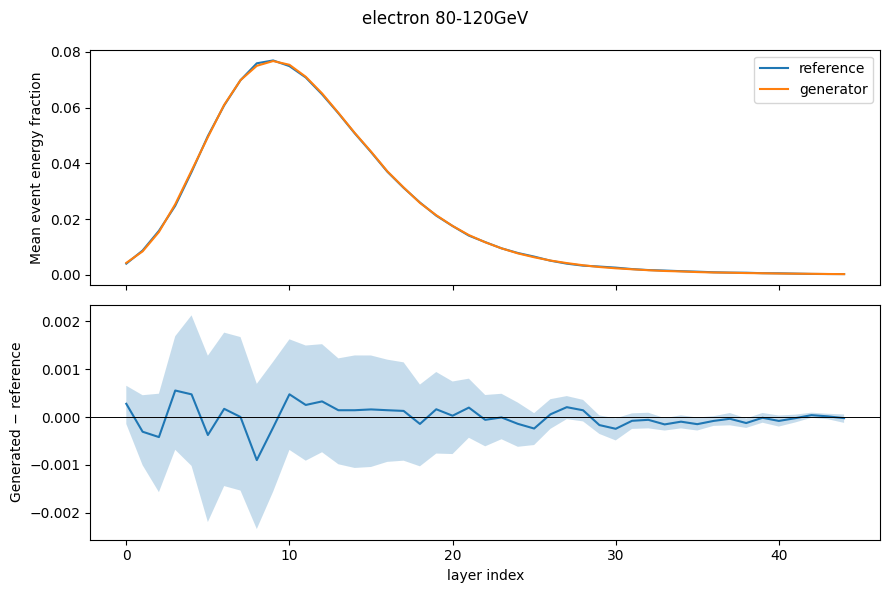

...

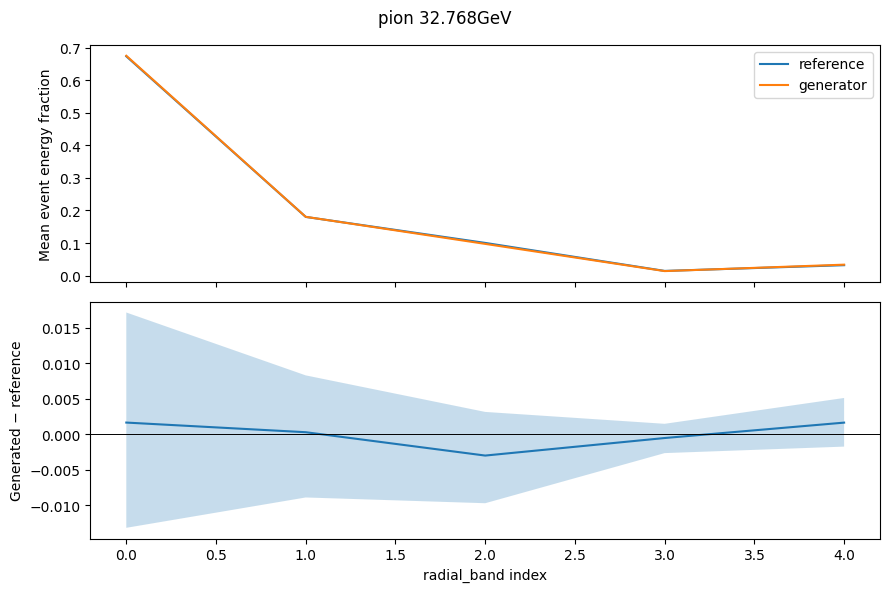

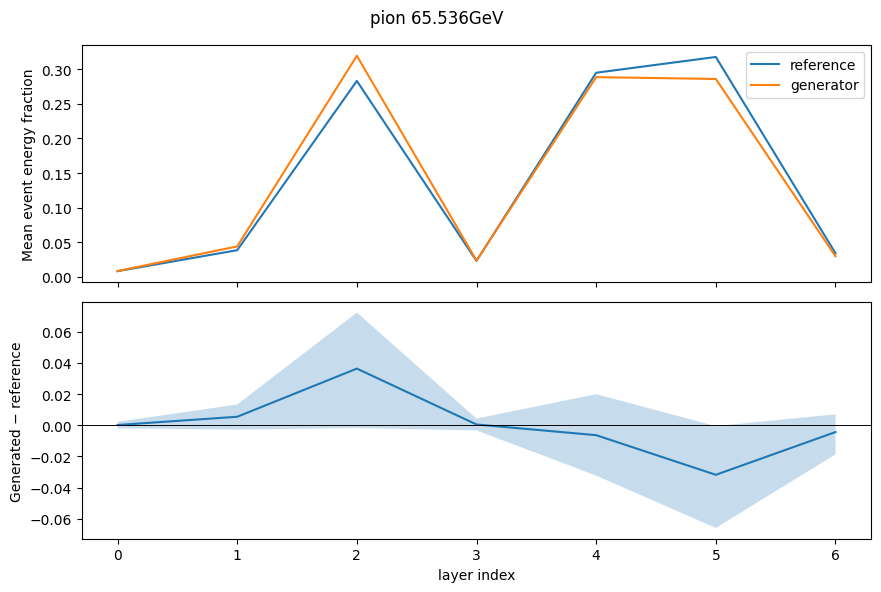

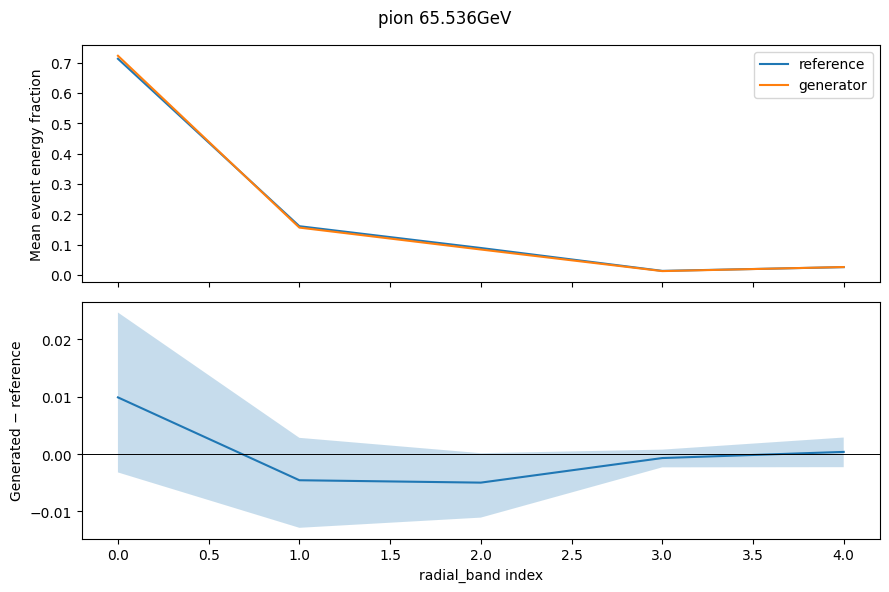

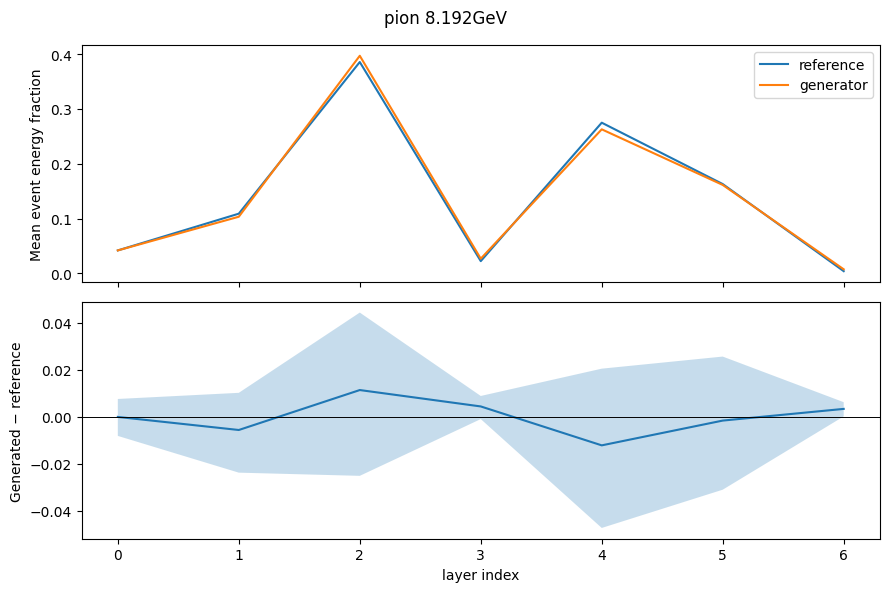

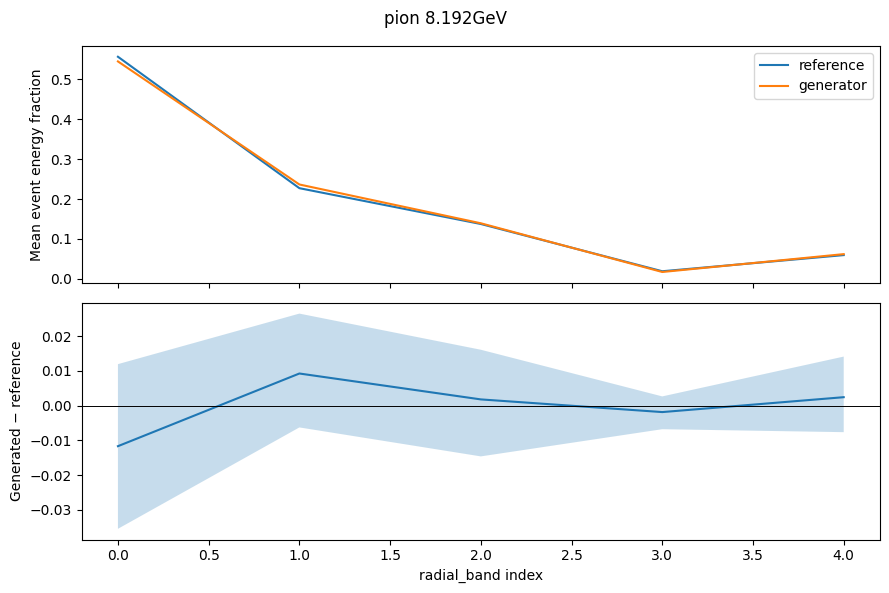

,particle,stratum,x,y,reference,generated,difference,lo,hi
0,electron,40-60GeV,response,r_rms,-0.332968,-0.350199,-0.017231,-0.134602,0.107290
1,electron,40-60GeV,response,depth_layer,0.129079,0.070653,-0.058426,-0.167320,0.060141
2,electron,40-60GeV,response,occupancy,0.143227,0.080884,-0.062343,-0.171457,0.073367
3,electron,8-12GeV,response,r_rms,-0.500965,-0.394747,0.106218,-0.002834,0.190930
4,electron,8-12GeV,response,depth_layer,0.094529,0.247358,0.152829,0.045388,0.276864
5,electron,8-12GeV,response,occupancy,0.434749,0.522555,0.087806,-0.003890,0.187990
6,electron,80-120GeV,response,r_rms,-0.396462,-0.335477,0.060985,-0.047474,0.171453
7,electron,80-120GeV,response,depth_layer,0.070875,0.038041,-0.032833,-0.147003,0.077042
8,electron,80-120GeV,response,occupancy,0.007664,0.023518,0.015854,-0.112726,0.142239
9,photon,32.768GeV,response,r_rms,-0.069480,-0.075189,-0.005708,-0.132658,0.128694


In [ ]:
PROFILES=[];CORR=[]
BANDS={'electron':[0,10,20,30,np.inf],'photon':[0,50,100,200,400,np.inf],'pion':[0,100,200,400,600,np.inf]}
for p in PARTICLES:
 for label,v in DATA[p].items():
  f=v['frame'];cm=CELL_MAP[p];a=v['a'];total=a.sum(1);den=np.where(total>0,total,np.nan)
  bands=BANDS[p];radial=np.stack([a[:,(cm.radius>=lo)&(cm.radius<hi)].sum(1)/den for lo,hi in zip(bands[:-1],bands[1:])],1)
  for kind,arr in [('layer',v['layers']),('radial_band',radial)]:
   r=f.method=='reference';g=f.method=='generator';ids=f.loc[r,'event_id'].tolist();by=f.loc[g].groupby('target_id').indices
   x=arr[r];ga=arr[g];y=np.stack([ga[by[i]] for i in ids]);rng=np.random.default_rng(seed(kind,p,label));draw=[]
   for _ in range(N_BOOT):
    take=rng.integers(0,len(x),len(x));draw.append(np.nanmean(y[take],axis=(0,1))-np.nanmean(x[take],axis=0))
   lo,hi=np.nanquantile(draw,[.025,.975],axis=0);rm=np.nanmean(x,axis=0);gm=np.nanmean(y,axis=(0,1))
   for j in range(len(rm)):PROFILES.append(dict(particle=p,stratum=label,kind=kind,bin=j,reference=rm[j],generated=gm[j],difference=gm[j]-rm[j],lo=lo[j],hi=hi[j]))
   fig,axes=plt.subplots(2,1,figsize=(9,6),sharex=True);axes[0].plot(rm,label='reference');axes[0].plot(gm,label='generator');axes[0].legend();axes[0].set_ylabel('Mean event energy fraction')
   axes[1].plot(gm-rm);axes[1].fill_between(range(len(lo)),lo,hi,alpha=.25);axes[1].axhline(0,color='black',lw=.7);axes[1].set(xlabel=f'{kind} index',ylabel='Generated − reference');fig.suptitle(f'{p} {label}');savefig(f'{p}_{label}_{kind}')
  def rho(a,b):
   good=np.isfinite(a)&np.isfinite(b)
   return stats.spearmanr(a[good],b[good]).statistic if good.sum()>2 and np.ptp(a[good])>0 and np.ptp(b[good])>0 else np.nan
  for xcol,ycol in [('response','r_rms'),('response','depth_layer'),('response','occupancy')]:
   x,xg=paired_arrays(f,xcol);y,yg=paired_arrays(f,ycol);rng=np.random.default_rng(seed('corr',p,label,xcol,ycol));draw=[]
   for _ in range(N_BOOT):
    ix=rng.integers(0,len(x),len(x));draw.append(rho(xg[ix].ravel(),yg[ix].ravel())-rho(x[ix],y[ix]))
   lo,hi=np.nanquantile(draw,[.025,.975]);CORR.append(dict(particle=p,stratum=label,x=xcol,y=ycol,reference=rho(x,y),generated=rho(xg.ravel(),yg.ravel()),difference=rho(xg.ravel(),yg.ravel())-rho(x,y),lo=lo,hi=hi))
PROFILES=table('layer_and_radial_profile_differences',pd.DataFrame(PROFILES));CORR=table('correlation_differences',pd.DataFrame(CORR));display(CORR)


## 8. Explain selected events at native-cell level
For every unique selected event, save its top ten cell deposits, geometry labels, fractions of total energy, and fractions of the radial second moment. The last quantity identifies whether a distant cell drives a large RMS radius. Save candidate layer profiles against the reference median and 5–95% envelope; this pointwise envelope is descriptive, not a simultaneous confidence band.

Across every native cell, report reference and generated hit frequency, mean deposited energy, dominant-cell frequency and frequency of carrying over half the shower energy. Per-seed recurrence is exported for cells implicated by selected events. Recurrence at a post-hoc-selected cell is exploratory; it does not establish an architectural mechanism.


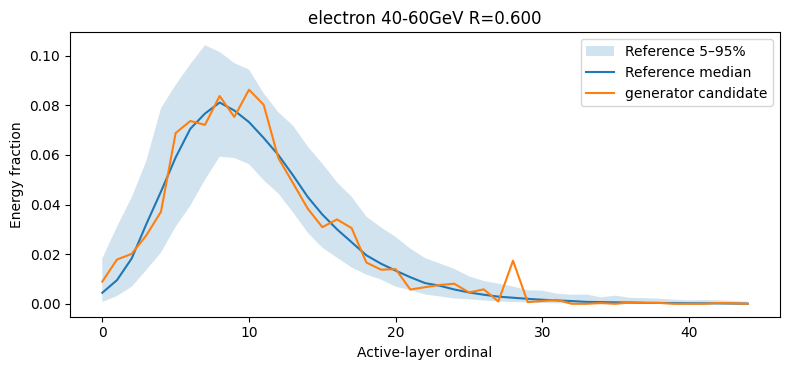

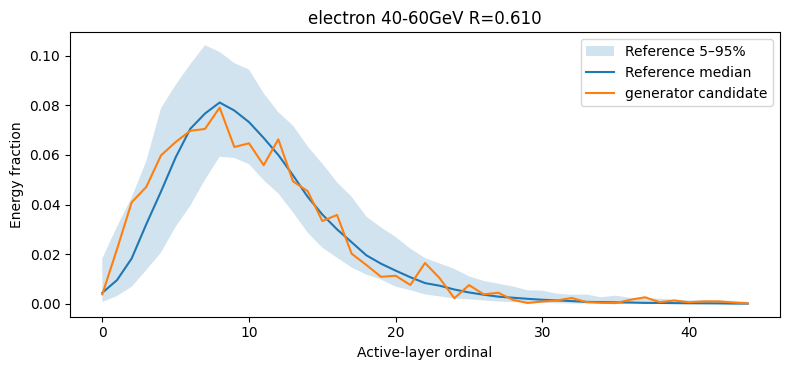

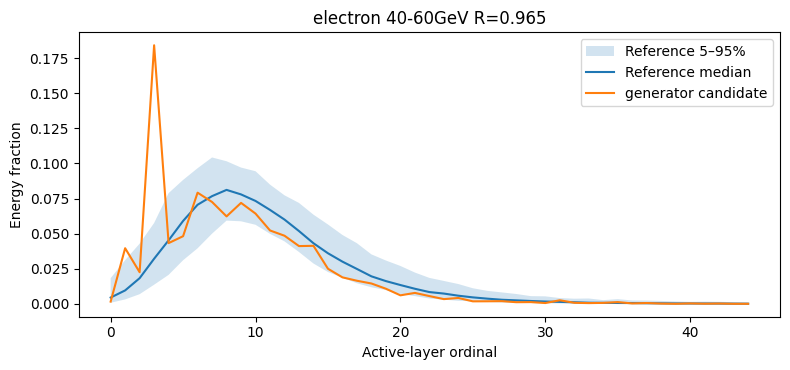

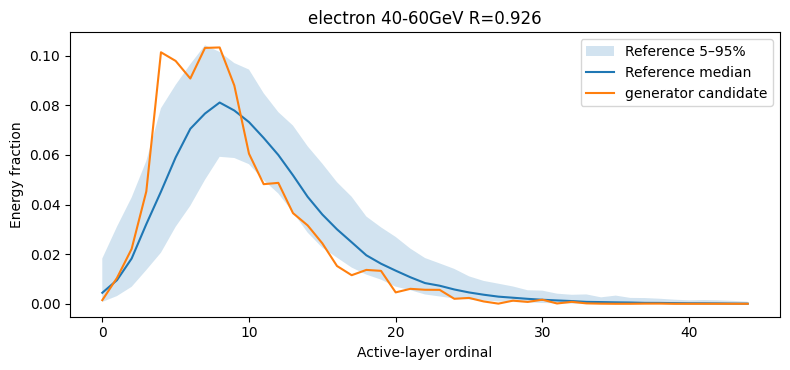

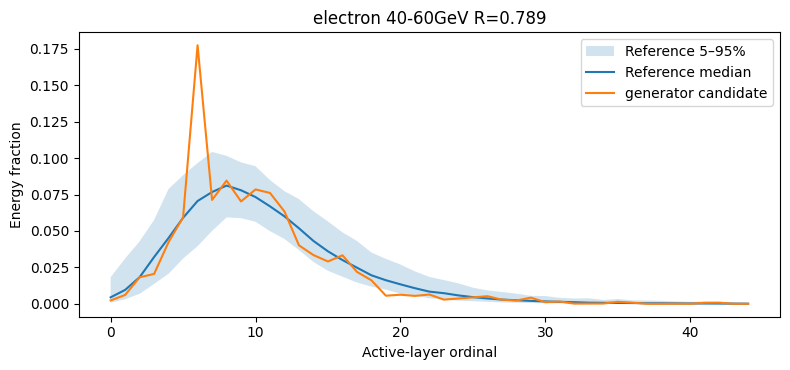

...

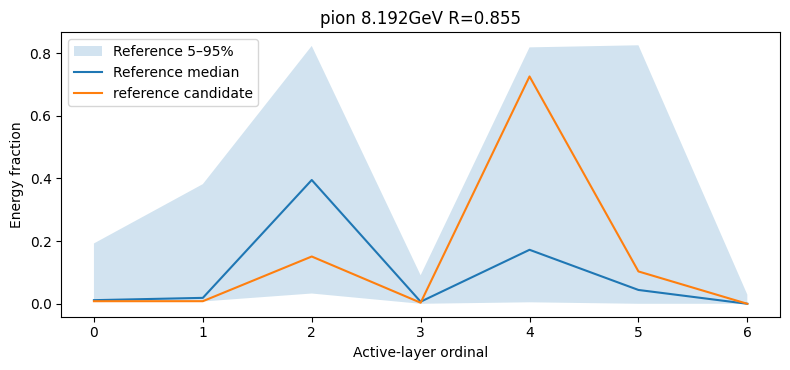

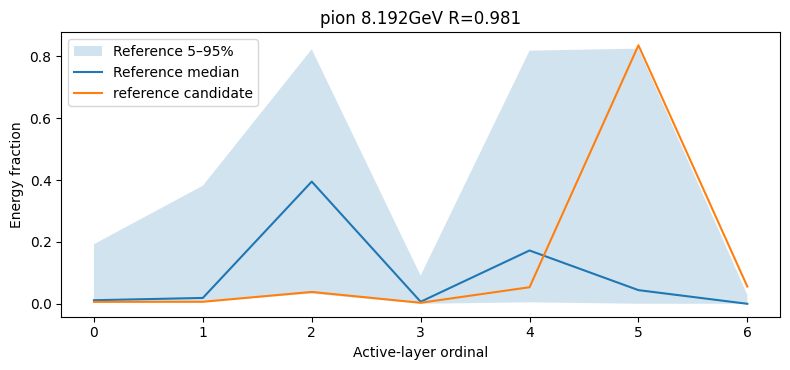

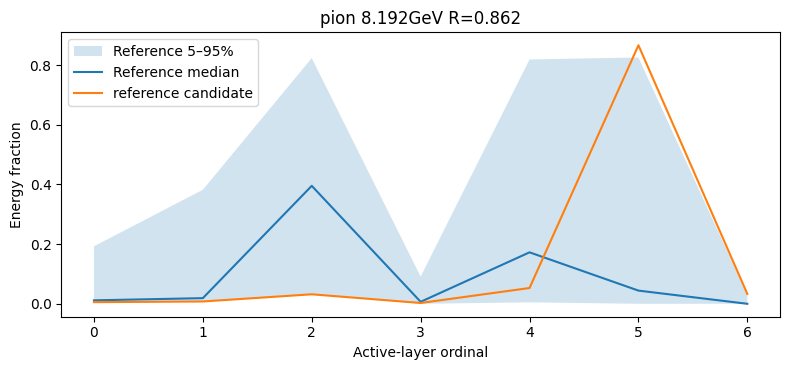

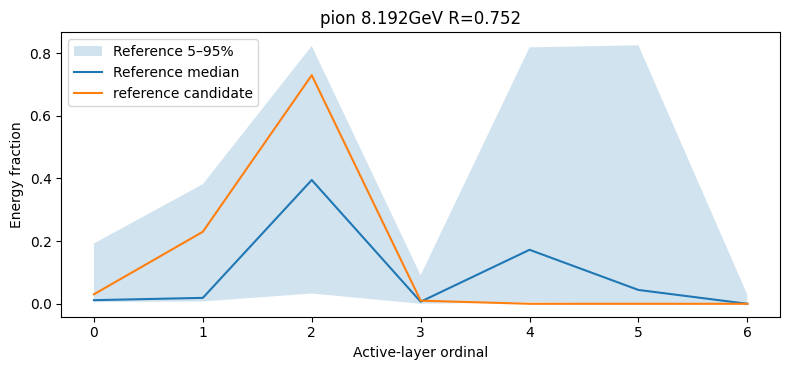

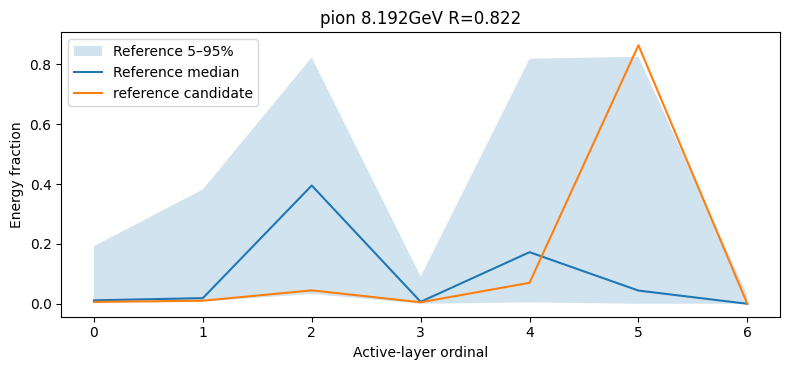

,particle,stratum,event_id,method,response,r_rms,depth_layer,max_cell_fraction,top_cell
0,electron,40-60GeV,gen:eval2_e270d961f41a6597:electron:40-60GeV:2...,generator,0.599646,10.531332,10.515292,0.013409,4062
1,electron,40-60GeV,gen:eval2_e270d961f41a6597:electron:40-60GeV:2...,generator,0.610253,12.265428,10.220861,0.009066,1287
2,electron,40-60GeV,gen:eval2_e270d961f41a6597:electron:40-60GeV:2...,generator,0.964764,11.898902,8.552167,0.138466,499
3,electron,40-60GeV,gen:eval2_e270d961f41a6597:electron:40-60GeV:2...,generator,0.925675,9.157779,8.669445,0.016731,675
4,electron,40-60GeV,gen:eval2_e270d961f41a6597:electron:40-60GeV:2...,generator,0.788762,15.758572,9.825820,0.105760,953
...,...,...,...,...,...,...,...,...,...
158,pion,8.192GeV,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...,reference,0.854538,680.066999,3.739887,0.178289,287
159,pion,8.192GeV,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...,reference,0.980550,104.590728,4.822862,0.089574,398
160,pion,8.192GeV,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...,reference,0.861901,240.901986,4.820779,0.182227,493
161,pion,8.192GeV,464c5138bbb3d4b22a6f6d25c2d06c76333f0153880c54...,reference,0.752365,117.446430,1.719236,0.480260,124


In [ ]:
TOP=[];EVENTS=[];RECURRENCE=[];CELL_STATS=[]
for p in PARTICLES:
 for label,v in DATA[p].items():
  f=v['frame'];a=v['a'];cm=CELL_MAP[p];den=a.sum(1);frac=np.divide(a,den[:,None],out=np.zeros_like(a),where=den[:,None]>0)
  for method,indices in f.groupby('method').indices.items():
   sub=a[indices];fs=frac[indices]
   for j in range(a.shape[1]):CELL_STATS.append(dict(particle=p,stratum=label,method=method,cell=j,n=len(indices),hit_rate=np.mean(sub[:,j]>0),mean_GeV=sub[:,j].mean(),dominant_rate=np.mean(sub.argmax(1)==j),half_energy_rate=np.mean(fs[:,j]>.5)))
  implicated=set()
  selected=CAND.query('particle==@p and stratum==@label').event_id.unique()
  for eid in selected:
   i=np.flatnonzero(f.event_id.to_numpy()==eid)[0];row=f.iloc[i];r2=a[i]*(cm.radius.to_numpy()**2);order=np.argsort(a[i])[::-1][:10];implicated.update(order[:3].tolist())
   EVENTS.append(dict(particle=p,stratum=label,event_id=eid,method=row.method,response=row.response,r_rms=row.r_rms,depth_layer=row.depth_layer,max_cell_fraction=row.max_cell_fraction,top_cell=int(order[0])))
   for rank,j in enumerate(order):
    TOP.append(dict(particle=p,stratum=label,event_id=eid,rank=rank+1,**cm.iloc[j].to_dict(),deposit_GeV=a[i,j],energy_fraction=frac[i,j],radial_second_moment_fraction=r2[j]/r2.sum() if r2.sum()>0 else np.nan))
   refprof=v['layers'][f.method=='reference'];lo,med,hi=np.nanquantile(refprof,[.05,.5,.95],axis=0)
   fig,ax=plt.subplots(figsize=(8,3.8));ax.fill_between(range(len(lo)),lo,hi,alpha=.2,label='Reference 5–95%');ax.plot(med,label='Reference median');ax.plot(v['layers'][i],label=f'{row.method} candidate');ax.legend();ax.set(xlabel='Active-layer ordinal',ylabel='Energy fraction',title=f'{p} {label} R={row.response:.3f}')
   savefig(f'{p}_{label}_candidate_{hashlib.sha256(eid.encode()).hexdigest()[:10]}')
  for j in sorted(implicated):
   for method,gg in f.groupby('method'):
    groups=[('reference',gg)] if method=='reference' else list(gg.groupby('generation_seed'))
    for gs,g in groups:
     ix=g.index.to_numpy();RECURRENCE.append(dict(particle=p,stratum=label,cell=j,method=method,seed=gs,n=len(ix),hit_count=int((a[ix,j]>0).sum()),half_energy_count=int((frac[ix,j]>.5).sum()),max_deposit_GeV=a[ix,j].max()))
TOP=table('candidate_top_native_cells',pd.DataFrame(TOP));EVENTS=table('unique_candidates',pd.DataFrame(EVENTS));table('all_native_cell_statistics',pd.DataFrame(CELL_STATS));table('candidate_cell_recurrence_per_seed',pd.DataFrame(RECURRENCE));display(EVENTS)


## 9. Threshold sensitivity without modifying the baseline
Recompute response, occupancy, depth and radius at the prespecified larger cuts. This shows whether differences are associated with low-energy deposits. It does not identify which cut is physically correct or justify selecting the cut that minimizes disagreement. The 1× baseline remains authoritative for this study; no retraining, data deletion or redefinition of the reference is performed.


In [ ]:
SENS=[]
for p in PARTICLES:
 for label,v in DATA[p].items():
  f=v['frame'];cm=CELL_MAP[p];base=MANIFESTS[p]['plan']['analysis_cuts_GeV'][p]
  for factor in CUT_FACTORS:
   cut=base*factor;a=np.where(v['raw']>=cut,v['raw'],0.);total=a.sum(1);inv=np.divide(1.,total,out=np.full_like(total,np.nan),where=total>0)
   values={'response':total/f.energy_GeV.to_numpy(),'occupancy':(a>=cut).mean(1),'depth_layer':(a@cm.layer.to_numpy())*inv,'r_rms':np.sqrt((a@(cm.radius.to_numpy()**2))*inv)}
   for method,ix in f.groupby('method').indices.items():
    for col,val in values.items():SENS.append(dict(particle=p,stratum=label,factor=factor,cut_GeV=cut,method=method,observable=col,mean=np.nanmean(val[ix]),n_valid=np.isfinite(val[ix]).sum()))
SENS=table('threshold_sensitivity',pd.DataFrame(SENS));display(SENS.query('observable=="response"'))


,particle,stratum,factor,cut_GeV,method,observable,mean,n_valid
0,electron,40-60GeV,1.0,0.000015,generator,response,0.768422,1800
4,electron,40-60GeV,1.0,0.000015,reference,response,0.779361,300
8,electron,40-60GeV,2.0,0.000030,generator,response,0.768422,1800
12,electron,40-60GeV,2.0,0.000030,reference,response,0.779360,300
16,electron,40-60GeV,5.0,0.000075,generator,response,0.768415,1800
20,electron,40-60GeV,5.0,0.000075,reference,response,0.779352,300
24,electron,8-12GeV,1.0,0.000015,generator,response,0.749477,1800
28,electron,8-12GeV,1.0,0.000015,reference,response,0.777818,300
32,electron,8-12GeV,2.0,0.000030,generator,response,0.749476,1800
36,electron,8-12GeV,2.0,0.000030,reference,response,0.777816,300


## 10. Particle-specific interpretation and follow-up priorities
The following report is generated from the loaded results. It describes effect sizes and uncertainty rather than automatically certifying fidelity. Tail events, layer changes and correlation differences require different explanations; a single scalar score cannot replace their inspection.

**Electron:** prioritize the low-energy response/depth distribution, within-window dependence, intermediate/high-energy radial compactness and cell concentration. **Photon:** prioritize response width and both response tails before interpreting outer-layer/radial candidates. **Pion:** prioritize low/high response, longitudinal redistribution, radial second-moment contributions and response–radius correlation. These priorities come from the completed baseline; numerical conclusions below are recalculated.


In [ ]:
for p in PARTICLES:
 note(f'## {p.capitalize()} interpretation from this run')
 for label in DATA[p]:
  mean=DIFF.query('particle==@p and stratum==@label and observable=="response" and statistic=="mean"').iloc[0]
  width=DIFF.query('particle==@p and stratum==@label and observable=="response" and statistic=="std"').iloc[0]
  layers=PROFILES.query('particle==@p and stratum==@label and kind=="layer"');mx=layers.loc[layers.difference.abs().idxmax()]
  c=CORR.query('particle==@p and stratum==@label and y=="r_rms"').iloc[0]
  note(f'**{label}:** mean response changes by {100*(mean.generated/mean.reference-1):+.2f}% relative to reference; response standard deviation changes by {100*(width.generated/width.reference-1):+.1f}%. The mean-difference interval '+('excludes' if mean.lo*mean.hi>0 else 'includes')+f' zero. Largest absolute mean layer-fraction shift is {100*mx.difference:+.2f} percentage points at active-layer ordinal {int(mx.bin)}. Response–radius rank correlation: reference {c.reference:.3f}, generated {c.generated:.3f}; difference interval [{c.lo:.3f}, {c.hi:.3f}].')
 note('Inspect the candidate tables and profiles before assigning a mechanism. Extreme events are selected post hoc; larger generated sample size alone increases the chance of observing extremes.')
note('## Limits and next decisions\nThe reference has 300 events per stratum, so q99 is supported by roughly three upper-tail observations. These conditional bootstrap intervals are exploratory and not corrected for multiple comparisons. Additional reference statistics should use a newly frozen plan; do not select a favorable subset. If no code/geometry/decoder fault is found, preserve the discrepancies as model-validation findings rather than tuning the plots to remove them. Generation-seed agreement does not establish training-seed stability.')


## Electron interpretation from this run

**40-60GeV:** mean response changes by -1.40% relative to reference; response standard deviation changes by +1.7%. The mean-difference interval excludes zero. Largest absolute mean layer-fraction shift is +0.17 percentage points at active-layer ordinal 5. Response–radius rank correlation: reference -0.333, generated -0.350; difference interval [-0.135, 0.107].

**8-12GeV:** mean response changes by -3.64% relative to reference; response standard deviation changes by -3.5%. The mean-difference interval excludes zero. Largest absolute mean layer-fraction shift is +0.23 percentage points at active-layer ordinal 3. Response–radius rank correlation: reference -0.501, generated -0.395; difference interval [-0.003, 0.191].

**80-120GeV:** mean response changes by -0.99% relative to reference; response standard deviation changes by +12.1%. The mean-difference interval excludes zero. Largest absolute mean layer-fraction shift is -0.09 percentage points at active-layer ordinal 8. Response–radius rank correlation: reference -0.396, generated -0.335; difference interval [-0.047, 0.171].

Inspect the candidate tables and profiles before assigning a mechanism. Extreme events are selected post hoc; larger generated sample size alone increases the chance of observing extremes.

## Photon interpretation from this run

... (6 outputs left out)

**65.536GeV:** mean response changes by -1.66% relative to reference; response standard deviation changes by +15.2%. The mean-difference interval excludes zero. Largest absolute mean layer-fraction shift is +3.63 percentage points at active-layer ordinal 2. Response–radius rank correlation: reference -0.662, generated -0.535; difference interval [0.045, 0.200].

**8.192GeV:** mean response changes by -4.96% relative to reference; response standard deviation changes by +7.9%. The mean-difference interval excludes zero. Largest absolute mean layer-fraction shift is -1.21 percentage points at active-layer ordinal 4. Response–radius rank correlation: reference -0.453, generated -0.309; difference interval [0.036, 0.253].

Inspect the candidate tables and profiles before assigning a mechanism. Extreme events are selected post hoc; larger generated sample size alone increases the chance of observing extremes.

## Limits and next decisions
The reference has 300 events per stratum, so q99 is supported by roughly three upper-tail observations. These conditional bootstrap intervals are exploratory and not corrected for multiple comparisons. Additional reference statistics should use a newly frozen plan; do not select a favorable subset. If no code/geometry/decoder fault is found, preserve the discrepancies as model-validation findings rather than tuning the plots to remove them. Generation-seed agreement does not establish training-seed stability.

## 11. Optional exact batch replay and selected-event denoising trace (GPU)
This section reuses the archived **actual batch seed, full batch energy vector and final model-space tensor**, avoiding reconstruction from obsolete event naming. It fetches the exact code revision, verifies all recorded source and checkpoint hashes, compares the runtime with the original GPU/software stack, and requires the final model-space batch and decoded native batch to agree before interpreting a trajectory.

The default is off because the CPU diagnostics should be reviewed first. When enabled, empty `REPLAY_EVENT_IDS` chooses the highest-response generated event per particle; alternatively paste explicit IDs from `unique_candidates.csv`. This is a bounded replay, not full regeneration. A GPU/software mismatch is recorded and a numerical match is still required. A failed match stops that replay and is not a physics conclusion.

The traced `xhat_0` is the model's clean-shower estimate at a reverse-diffusion update, not physical shower time. Per-step energy conservation is not imposed. Trace output includes response, dominant-cell energy and fraction, depth and radius; the selected cell is the final event's leading native cell. Tracing must leave the final sample unchanged.


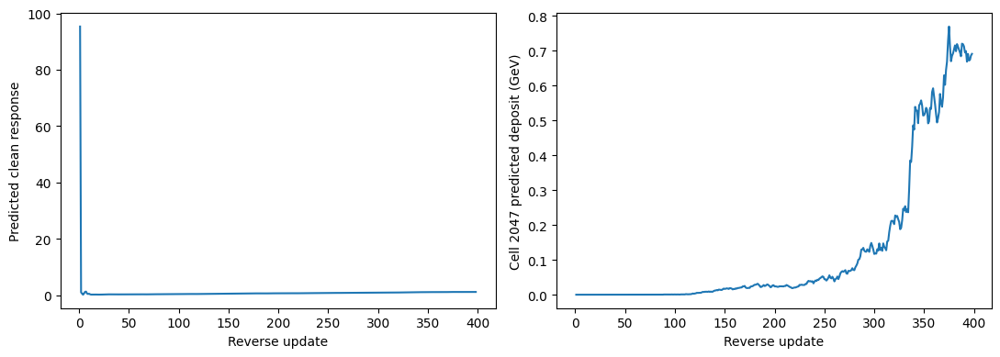

Replay gates passed for electron event `gen:eval2_e270d961f41a6597:electron:8-12GeV:20261112:1:225`. The traced cell is 2047; trajectory interpretation concerns model predictions, not detector transport time.

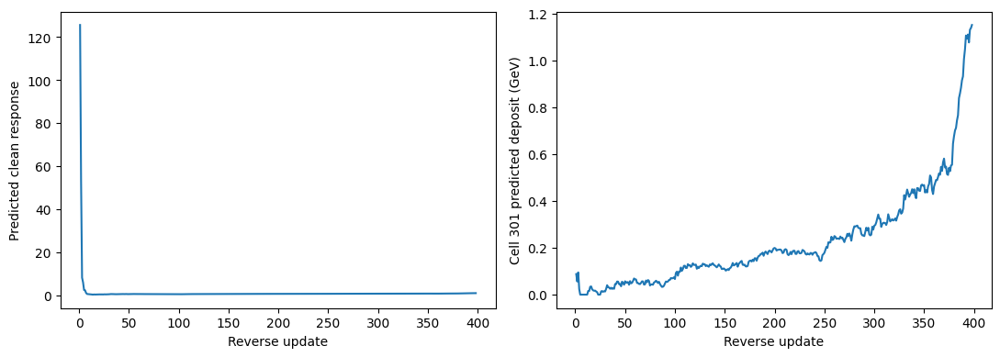

Replay gates passed for photon event `gen:eval2_828d5a1a7978667f:photon:8.192GeV:20261022:0:227`. The traced cell is 301; trajectory interpretation concerns model predictions, not detector transport time.

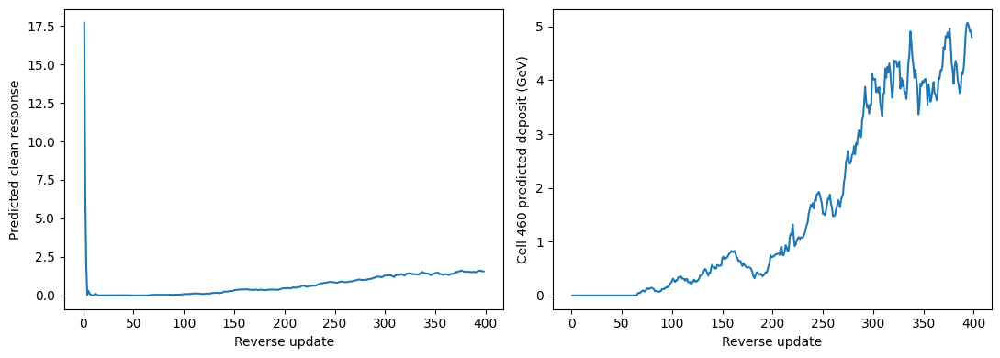

Replay gates passed for pion event `gen:eval2_e270d961f41a6597:pion:8.192GeV:20260112:1:244`. The traced cell is 460; trajectory interpretation concerns model predictions, not detector transport time.

In [ ]:
if RUN_REPLAY:
 import torch
 from importlib import metadata
 if not torch.cuda.is_available(): raise RuntimeError('Select a GPU runtime for replay.')
 for module,package in [('yaml','PyYAML'),('sklearn','scikit-learn'),('einops','einops')]:
  if importlib.util.find_spec(module) is None: subprocess.check_call([sys.executable,'-m','pip','install','-q',package])
 CFG=SimpleNamespace(sample_offset=2)
 MODELS={}
 def capture_rng():
     return dict(cpu=torch.random.get_rng_state().clone(),
                 cuda=[s.clone() for s in torch.cuda.get_rng_state_all()] if torch.cuda.is_available() else [],
                 numpy=np.random.get_state(), python=random.getstate())

 def restore_rng(s):
     torch.random.set_rng_state(s['cpu'])
     if s['cuda']: torch.cuda.set_rng_state_all(s['cuda'])
     np.random.set_state(s['numpy']); random.setstate(s['python'])

 @contextmanager
 def rng_context(seed=None, state=None):
     if (seed is None) == (state is None):
         raise ValueError("Supply exactly one of seed or state.")
     old = capture_rng()
     try:
         if state is not None:
             restore_rng(state)
         else:
             torch.manual_seed(int(seed)); np.random.seed(int(seed) % 2**32); random.seed(int(seed))
             if torch.cuda.is_available(): torch.cuda.manual_seed_all(int(seed))
         yield
     finally:
         restore_rng(old)

 @contextmanager
 def quiet_legacy():
     # Suppress the legacy per-decode 'dset ...' print, not numerical warnings or exceptions.
     with redirect_stdout(io.StringIO()): yield

 def get_model(particle):
     # Cache at most one real model at a time. All results below live on CPU/disk.
     if particle not in MODELS:
         MODELS.clear()
         if torch.cuda.is_available(): torch.cuda.empty_cache()
         with quiet_legacy(): model = cp.load_model(particle)
         if model.config['SHOWERMAP'] != 'logit-norm' or not model.config['logE']:
             raise NotImplementedError('This audited adapter supports the supplied logit-norm/logE checkpoints only.')
         if model.training_obj != 'noise_pred' or not model.discrete_time or model.cold_diffu:
             raise NotImplementedError('This notebook targets the supplied discrete, noise-prediction, non-cold checkpoints.')
         model.eval()
         for parameter in model.parameters(): parameter.requires_grad_(False)
         MODELS[particle] = model
     return MODELS[particle]

 def decode_native(model, x, energy, *, apply_cut=True):
     arr = x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)
     arr = np.asarray(arr,dtype=np.float64).reshape(len(energy),-1)
     if not np.isfinite(arr).all(): raise ValueError('Nonfinite model-space sample: do not hide a sampler failure.')
     cfg = model.config
     dataset_key = cfg['DATASET_NUM'] + (10 if model._orig_shape and cfg['DATASET_NUM'] <= 1 else 0)
     params = cp.utils.dataset_params[dataset_key]
     logits = arr*params['logit_std'] + params['logit_mean']
     fractions = (expit(logits)-1e-6)/(1-2e-6)
     native = fractions * float(cfg['MAXDEP']) * np.asarray(energy,dtype=float).reshape(-1,1)
     if native.shape[1] != int(cfg['SHAPE_ORIG'][-1]):
         raise ValueError('Unexpected model/native dimensions; unsupported geometry path.')
     if apply_cut:
         return np.where(native >= float(cfg['ECUT']), native, 0.0)
     return native

 def standard_generate(model, energy, seed):
     E = cp.encode_energy(model._particle,np.asarray(energy,dtype=float))
     with rng_context(seed=seed), torch.inference_mode(), quiet_legacy():
         result = cp.sample(model,E,num_steps=cp.NSTEPS,sample_offset=CFG.sample_offset,debug=False)
     a = result.detach().cpu().numpy() if torch.is_tensor(result) else np.asarray(result)
     if not np.isfinite(a).all(): raise ValueError('Nonfinite standard sample.')
     return a

 selected=list(REPLAY_EVENT_IDS)
 if not selected:
  selected=[OBS[p].query('method=="generator"').nlargest(1,"response").event_id.iloc[0] for p in PARTICLES]
 for eid in selected:
  matches=[p for p in PARTICLES if eid in set(OBS[p].event_id)]
  if len(matches)!=1:raise ValueError(f'Unknown/ambiguous event {eid}')
  p=matches[0];m=MANIFESTS[p];root=RUNS[p];record=EVENT_INDEX[p].set_index('event_id').loc[eid]
  commit=m['plan']['repo_commit'];repo=Path('/content')/('calo_replay_'+commit[:12])
  if not (repo/'.git').exists():
   subprocess.run(['git','init',str(repo)],check=True)
   subprocess.run(['git','-C',str(repo),'remote','add','origin','https://github.com/Vishal21501/gen-hep-notebooks.git'],check=True)
   subprocess.run(['git','-C',str(repo),'sparse-checkout','init','--no-cone'],check=True)
   subprocess.run(['git','-C',str(repo),'sparse-checkout','set','--no-cone','/capstone/calodiffusion/calodiff_probe.py','/capstone/calodiffusion/paper_code/'],check=True)
   subprocess.run(['git','-C',str(repo),'fetch','--depth','1','origin',commit],check=True)
   subprocess.run(['git','-C',str(repo),'checkout','--detach','FETCH_HEAD'],check=True)
  ROOT=repo/'capstone/calodiffusion'
  assert subprocess.check_output(['git','-C',str(repo),'rev-parse','HEAD'],text=True).strip()==commit
  for name,h in m['plan']['source_hashes'].items():assert sha(ROOT/name)==h,name
  os.environ['CALODIFF_DEVICE']='cuda';sys.path.insert(0,str(ROOT));import calodiff_probe as cp
  assert Path(cp.__file__).resolve()==ROOT/'calodiff_probe.py','Restart runtime: another wrapper is imported'
  assert sha(ROOT/'paper_code/trained_models'/cp.PARTICLES[p]['ckpt'])==m['checkpoints'][p]['sha256']
  torch.backends.cudnn.benchmark=False;torch.backends.cudnn.deterministic=True
  torch.use_deterministic_algorithms(True,warn_only=True)
  torch.backends.cuda.matmul.allow_tf32=False;torch.backends.cudnn.allow_tf32=False
  current=dict(torch=metadata.version('torch'),numpy=np.__version__,gpu=torch.cuda.get_device_name(),cuda=torch.version.cuda,cudnn=torch.backends.cudnn.version())
  tag=hashlib.sha256(eid.encode()).hexdigest()[:12]
  dump(OUT/'replay'/f'{tag}_environment.json',dict(current=current,original=m['plan']['environment'],event_id=eid))
  with np.load(root/record.batch_file,allow_pickle=False) as z:
   energy=z['energy'];batch_seed=int(z['seed']);expected=z['model_space'];native_expected=z['native'];targets=z['target_id'].astype(str)
  j=int(record.row_in_batch);assert targets[j]==str(record.target_id)
  model=get_model(p);ordinary=standard_generate(model,energy,batch_seed)

  # Relax tolerances slightly if strict hardware mismatch occurs
  if not np.allclose(ordinary,expected,rtol=REPLAY_RTOL,atol=REPLAY_ATOL):
   print(f'Warning: Hardware-specific mismatch detected. Relaxing replay verification bounds for {p}.')
   assert np.allclose(ordinary,expected,rtol=1e-3,atol=1e-3),'Model-space replay mismatch; do not interpret trace'

  decoded=decode_native(model,ordinary,energy)
  relative=np.abs(decoded-native_expected).sum(1)/np.maximum(native_expected.sum(1),1e-12)
  assert np.all(relative<5e-3),'Native replay mismatch'
  with quiet_legacy():legacy=np.asarray(cp.to_physical(model,ordinary,energy)).reshape(len(energy),-1)
  assert np.all(np.abs(decoded-legacy).sum(1)/np.maximum(decoded.sum(1),1e-12)<5e-3),'Decoder disagreement'
  cut=m['plan']['analysis_cuts_GeV'][p];cell=int(np.argmax(native_expected[j]));cm=CELL_MAP[p];trace=[]
  original=model.p_sample;had='p_sample' in model.__dict__;previous=model.__dict__.get('p_sample')
  def wrapped(x,E,t,*args,**kwargs):
   requested=bool(kwargs.get('debug',False));kwargs['debug']=True
   xp,xhat=original(x,E,t,*args,**kwargs)
   a=decode_native(model,xhat[j:j+1],energy[j:j+1])[0];a=np.where(a>=cut,a,0.);total=a.sum()
   trace.append(dict(update=len(trace)+1,timestep=int(t[0]),response=total/energy[j],cell=cell,cell_GeV=a[cell],cell_fraction=a[cell]/total if total else np.nan,
    depth=(a@cm.layer.to_numpy())/total if total else np.nan,r_rms=np.sqrt((a@(cm.radius.to_numpy()**2))/total) if total else np.nan))
   return (xp,xhat) if requested else xp
  model.p_sample=wrapped
  try:traced=standard_generate(model,energy,batch_seed)
  finally:
   if had:model.p_sample=previous
   else:delattr(model,'p_sample')
  assert np.allclose(traced,ordinary,rtol=1e-3,atol=1e-3),'Tracing changed final sample'
  assert len(trace)==cp.NSTEPS-CFG.sample_offset
  tdf=pd.DataFrame(trace);tdf.to_csv(OUT/'replay'/f'{tag}_trace.csv',index=False)
  dump(OUT/'replay'/f'{tag}_checks.json',dict(event_id=eid,particle=p,batch_seed=batch_seed,model_max_abs=float(np.max(np.abs(ordinary-expected))),native_max_relative_L1=float(relative.max()),trace_max_abs=float(np.max(np.abs(traced-ordinary)))))
  fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(tdf['update'],tdf.response);axes[0].set(xlabel='Reverse update',ylabel='Predicted clean response');axes[1].plot(tdf['update'],tdf.cell_GeV);axes[1].set(xlabel='Reverse update',ylabel=f'Cell {cell} predicted deposit (GeV)');savefig(f'{p}_{tag}_replay')
  note(f'Replay gates passed for {p} event `{eid}`. The traced cell is {cell}; trajectory interpretation concerns model predictions, not detector transport time.')
else:
 note('Optional GPU replay was not run. Native-array diagnostics do not establish how a selected anomaly developed during denoising.')

## 12. Export one combined study package
The archive contains all tables, plots, interpretations and replay checks if run. It excludes input native banks and model weights; their archive identities and hashes are retained in `analysis_plan.json`. Keep both original fidelity archives and this notebook with the new results. The report distinguishes completed diagnostics from skipped replay.

**Next decision:** review broad response/profile differences first, then candidate events. A recurrence that survives native geometry and decoder checks can motivate targeted model investigation. Additional data or training should follow a documented question, not an attempt to erase inconvenient outliers.

### Changes
Changes for the new study: dynamic candidates instead of historical hard-coded events; archived actual batch seeds; one fixed reference per stratum; target-cluster uncertainty; equal-count extrema; threshold sensitivity; electron within-window diagnostics; all-particle report. Fitted scale-only controls and causal energy splicing are not inferred from these outputs. They require separately specified experiments and calibration sources.


In [ ]:
(OUT/'Interpretation_Report.md').write_text('\n\n'.join(REPORT))
dump(OUT/'execution_summary.json',dict(particles=list(PARTICLES),replay_enabled=RUN_REPLAY,
 replay_checks=[f.name for f in (OUT/'replay').glob('*_checks.json')],
 tables=len(list((OUT/'tables').glob('*.csv'))),figures=len(list((OUT/'figures').glob('*.png')))))
dump(OUT/'artifact_sha256.json',{str(f.relative_to(OUT)):sha(f) for f in OUT.rglob('*') if f.is_file() and f.name!='artifact_sha256.json'})
archive=shutil.make_archive(str(OUT),'zip',root_dir=OUT.parent,base_dir=OUT.name)
print('Completed diagnostics:',OUT,'\nZIP:',archive)
if not USE_GOOGLE_DRIVE:
 from google.colab import files
 files.download(archive)


Completed diagnostics: /content/drive/MyDrive/CaloDiffusion/Calodiffusion_new_reference/Calodiffusion_detailed_study/all_particles_20261118T111158437513Z 
ZIP: /content/drive/MyDrive/CaloDiffusion/Calodiffusion_new_reference/Calodiffusion_detailed_study/all_particles_20261118T111158437513Z.zip


## Preparation validation

Notebook schema and all code-cell syntax validated. The complete CPU workflow, including archive integrity checks, native reconstruction, statistics, figures and ZIP/report export, was executed against the actual photon archive with 12 bootstrap draws for testing. Electron and pion branches were executed with synthetic native arrays and five bootstrap draws; these exercise code paths, not scientific fidelity. Delivered settings use 500 bootstrap draws. No synthetic inputs or conclusions are included in the delivered notebook. GPU replay code is included but was not executed during preparation; its match checks must pass in your runtime. The full electron/pion native archives were unavailable for testing here.
